In [1]:
import sys
sys.path.append("..")

In [2]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))
print(torch.cuda.get_device_properties(0).total_memory / 1024**3)

True
NVIDIA A100-SXM4-40GB
39.4935302734375


In [3]:
%pip install h5py

Defaulting to user installation because normal site-packages is not writeable
  Obtaining dependency information for h5py from https://files.pythonhosted.org/packages/cb/92/a8851d936547efe30cc0ce5245feac01f3ec6171f7899bc3f775c72030b3/h5py-3.16.0-cp310-cp310-manylinux_2_28_x86_64.whl.metadata
  Using cached h5py-3.16.0-cp310-cp310-manylinux_2_28_x86_64.whl.metadata (3.0 kB)
Using cached h5py-3.16.0-cp310-cp310-manylinux_2_28_x86_64.whl (5.1 MB)
Note: you may need to restart the kernel to use updated packages.


In [2]:
import h5py
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from utils.das_dataset import DasDataset
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm
from utils.noise_scheduler import LinearNoiseScheduler 
from IPython.display import clear_output

In [3]:
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_files_noise = [das_data/"train_1000.h5"]#sorted(das_data.glob("train_*.h5"))
test_files_noise = [das_data/"test_1000.h5"]#sorted(das_data.glob("test_*.h5"))

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_noise = DasDataset(train_files_noise)
test_set_noise = DasDataset(test_files_noise)
train_loader_noise = DataLoader(train_set_noise, batch_size=16, shuffle=True)
test_loader_noise = DataLoader(test_set_noise, batch_size=16, shuffle=False)

In [4]:
from models.unet_with_temb import DDPM
model_noise =  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)

In [5]:
x = next(iter(train_loader_noise)).to(device)
scheduler = LinearNoiseScheduler(timesteps=1000, beta_start=1e-4,beta_end=0.02, device=device)
t = torch.randint(0,scheduler.betas.shape[0], (x.shape[0],), device= device).long()
with torch.no_grad():
    noise_prediction = model_noise(x,t)
print("shape of input: ", x.shape)
print("shape of output: ", noise_prediction.shape)

shape of input:  torch.Size([16, 1, 256, 512])
shape of output:  torch.Size([16, 1, 256, 512])


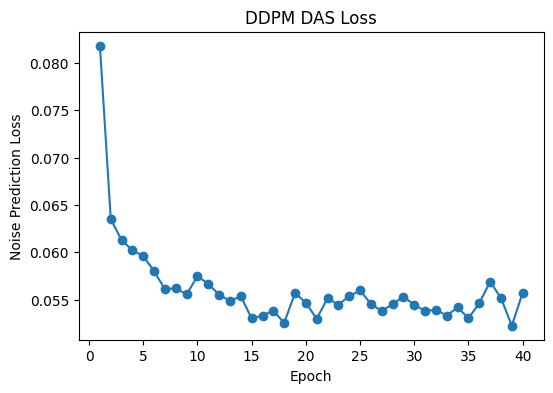

In [6]:
#from itertools import islice
checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)
model_das_path=checkpoints/"das_ddpm_noise_model.pth"
loss_plot_path=checkpoints/"das_ddpm_noise_loss.png"

optimizer= torch.optim.Adam(model_noise.parameters(), lr=1e-4)

epochs= 40 
train_losses=[]
start_epoch=0
#max_batches=1000
#limited_loader = islice(train_loader, max_batches)

if model_das_path.exists():
    checkpoint = torch.load(model_das_path,map_location=device)
    if "model_noise" in checkpoint:
        model_noise.load_state_dict(checkpoint["model_noise"])
    if "optimizer" in checkpoint:
        optimizer.load_state_dict(checkpoint["optimizer"])
    train_losses= checkpoint.get("train_losses", [])
    start_epoch=checkpoint.get("completed_epochs", len(train_losses)) 


for epoch in range(start_epoch, epochs):
    model_noise.train()
    epoch_loss= 0.0
    for batch in tqdm(train_loader_noise, desc=f"Epoch{epoch+1}/{epochs}"):

        #if batch_i >= max_batches: break

        x=batch.to(device)
        epsilon=torch.randn_like(x)
        t=torch.randint(0,scheduler.betas.shape[0],(x.shape[0],),device=device).long()
        xt=scheduler.add_noise(x0=x, epsilon=epsilon,t=t)
        noise_prediction=model_noise(xt,t)
        
        loss=((noise_prediction -epsilon)**2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss+= loss.item()

    avg_loss=epoch_loss/len(train_loader_noise)
    train_losses.append(avg_loss)
   
    torch.save({
    "model_noise": model_noise.state_dict(), "optimizer": optimizer.state_dict(),"train_losses":train_losses,
                  "completed_epochs": epoch+1, "base_channels": 64, "channels_multipilier": ( 1,1,2,2,4),
                  "normalizartion": {"function": "arcsinh", "s": 50.0, "A_max": 12350.0}
     }, model_das_path)
    
    clear_output(wait=True)
    plt.figure(figsize=(6,4))
    plt.plot(range(1,len(train_losses)+1), train_losses, marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Noise Prediction Loss")
    plt.title("DDPM DAS Loss")
    plt.savefig(loss_plot_path)
    plt.show()    

In [7]:
checkpoint_noise = torch.load(model_das_path, map_location = device)
model_noise.load_state_dict(checkpoint_noise["model_noise"])
model_noise = model_noise.to(device)

In [18]:
num_images = 2
xt = torch.randn(num_images, 1,256,512, device = device)
print(xt.shape)
timesteps_shown = [999, 600 , 300, 100, 0]

torch.Size([2, 1, 256, 512])


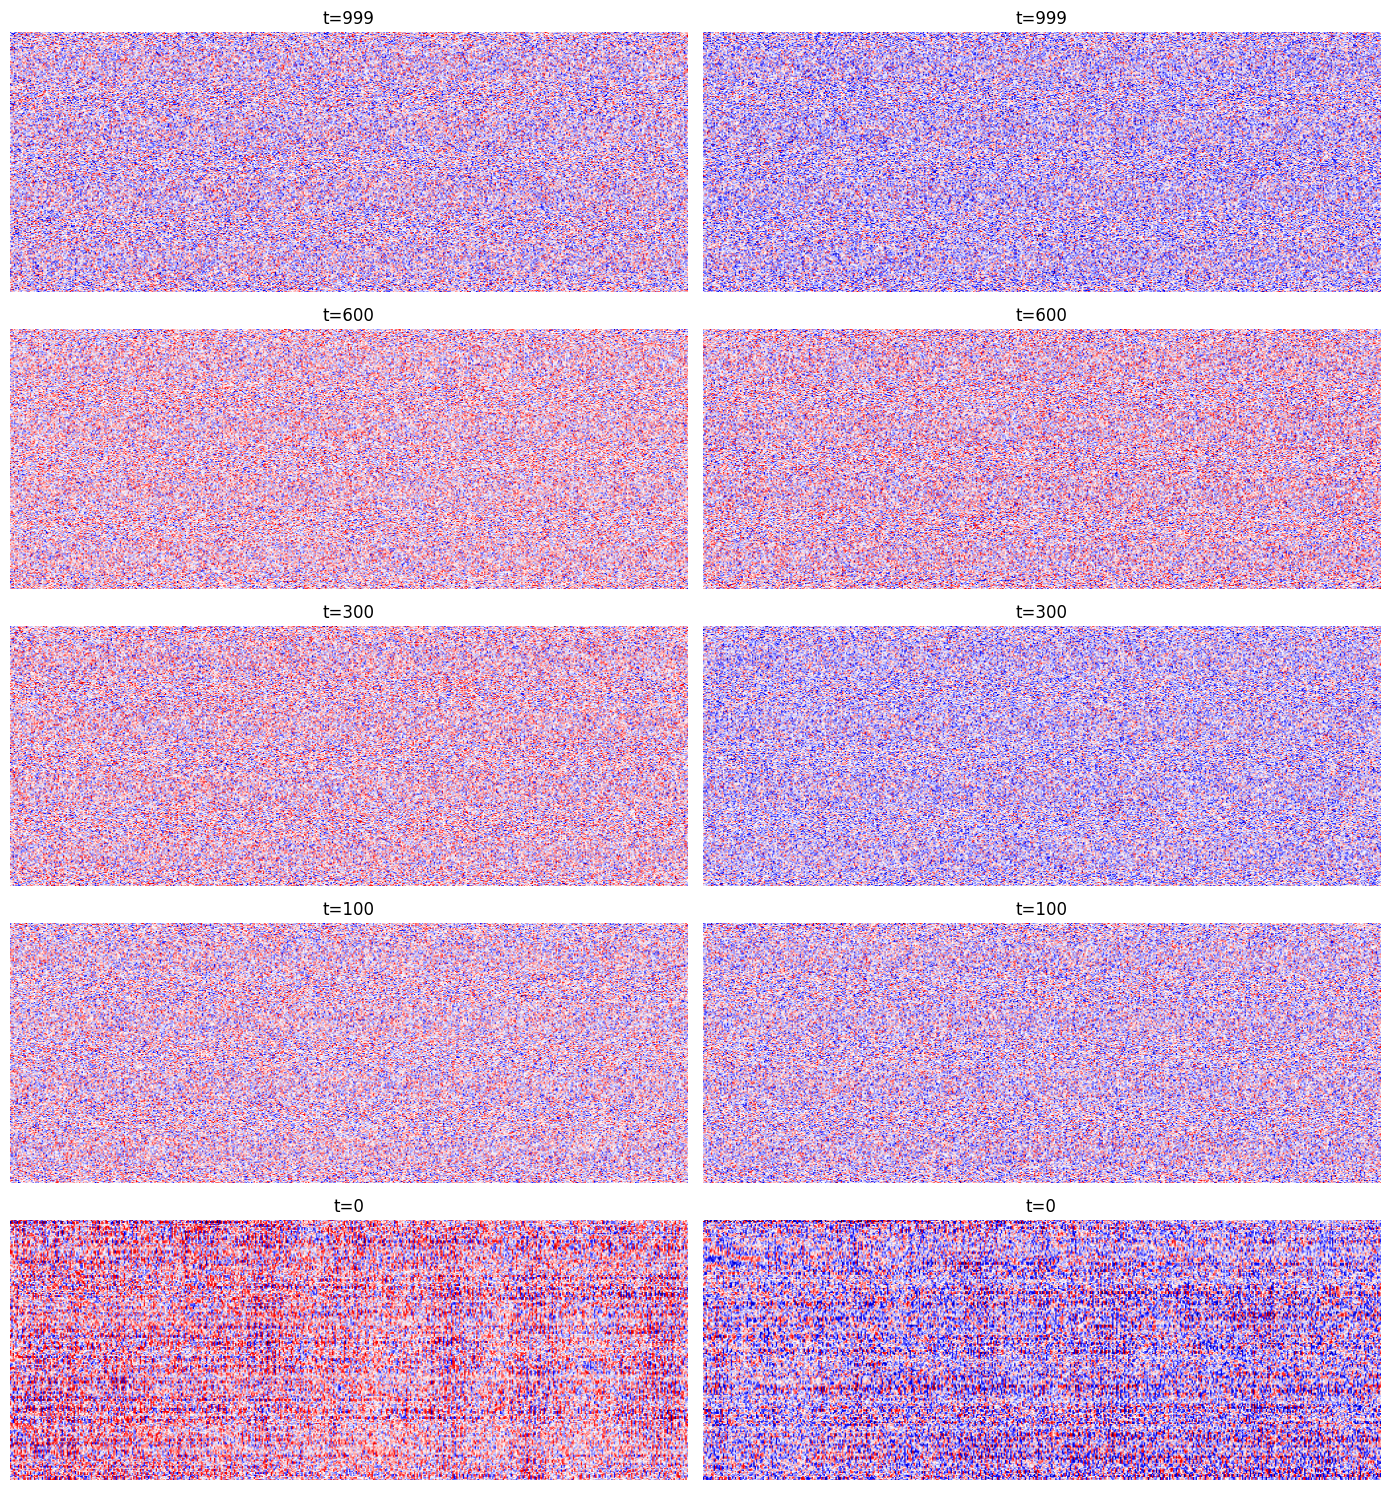

In [19]:
num_rows = len(timesteps_shown)
fig, axes = plt.subplots(num_rows, num_images, figsize = (7*num_images, 3*num_rows))
model_noise.eval()
with torch.no_grad():
    for step in reversed(range(scheduler.betas.shape[0])):
        if step in timesteps_shown:
            row= timesteps_shown.index(step)
            for i in range(num_images):
                axes[row,i].imshow(xt[i,0].detach().cpu(), aspect="auto", cmap="seismic") 
                axes[row,i].axis("off")
                axes[row,i].set_title(f"t={step}")
        t=torch.full((num_images,),step, device=device, dtype= torch.long)
        predicted_noise=model_noise(xt,t)
        xt,x0_predicted=scheduler.reverse_sampling_step(xt,predicted_noise,step)
plt.tight_layout()
plt.show()   

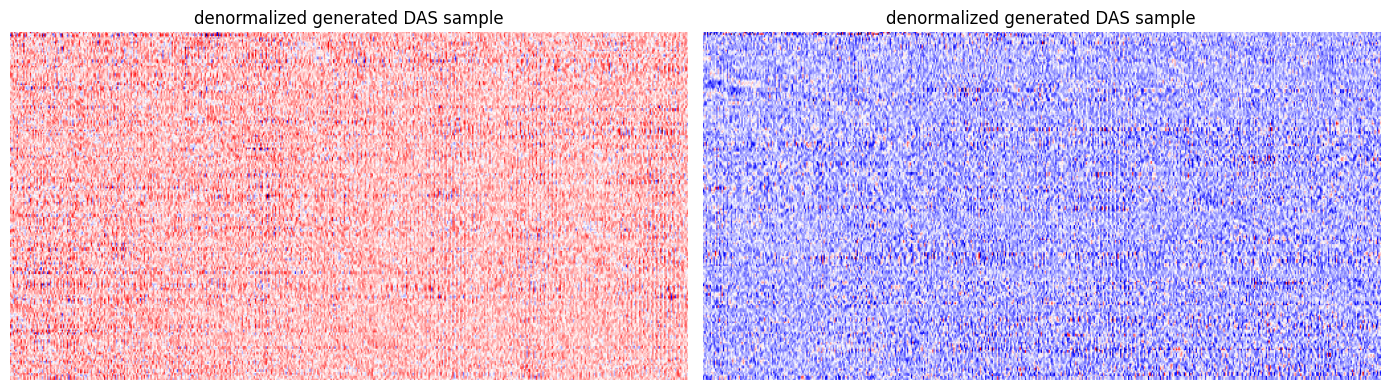

In [23]:
from utils.normalizer import denormalize
denormalized = denormalize(xt)
fig1, axes1 = plt.subplots(1, num_images, figsize = (7*num_images,4))
for i in range(num_images):
                axes1[i].imshow(denormalized[i,0].detach().cpu(), aspect="auto", cmap="seismic" ) 
                axes1[i].axis("off")
                axes1[i].set_title("denormalized generated DAS sample")
plt.tight_layout()
plt.show()                

In [32]:

percentiles=[50,60,99,99.9,99.99]
#normalized
x_test = next(iter(test_loader_noise))[:num_images].to(device)
#denomalized
x_test = denormalize(x_test).detach().cpu().numpy()
denormalized_tensor = denormalize(xt[:num_images])
denormalized_tensor= denormalized_tensor[:num_images].detach().cpu().numpy()

x_test_percentiles = np.percentile(np.abs(x_test).reshape(-1), percentiles)
denormalized_percentiles = np.percentile(np.abs(denormalized_tensor).reshape(-1), percentiles)

for i in range (len(percentiles)):
    print(
        f"{percentiles[i]}% |" f" real DAS: {x_test_percentiles[i]:.2f} |" f" generated DAS {denormalized_percentiles[i]:.2f}"
    )


50% | real DAS: 37.42 | generated DAS 30.81
60% | real DAS: 48.96 | generated DAS 38.78
99% | real DAS: 265.04 | generated DAS 137.69
99.9% | real DAS: 473.50 | generated DAS 197.63
99.99% | real DAS: 890.30 | generated DAS 274.39
